# DeepSeek Sparse Attention: let a tiny scorer choose which tokens to read

*DeepSeek-AI, "DeepSeek-V3.2: Pushing the Frontier of Open Large Language Models", section 2.1 ([arXiv 2512.02556](https://arxiv.org/abs/2512.02556)); first released as DeepSeek-V3.2-Exp (Sep 2025). Used by GLM-5. Notebook 4 of 9 in the "How LLMs build on each other" series.*

**TL;DR.** Full attention makes every token compare itself with every earlier token, which costs $O(L^2)$. **DeepSeek Sparse Attention (DSA)** keeps the whole context in the cache but lets each token read only the **top-$k$ most relevant** earlier tokens (DeepSeek-V3.2 uses $k=2048$ at a context of up to 128K). Who is relevant is decided by a small separate network, the **lightning indexer**: a handful of tiny heads that score every earlier token cheaply. The indexer is trained to imitate where the full attention would have looked. Main attention then costs $O(Lk)$ instead of $O(L^2)$; the indexer is still $O(L^2)$ but with a much smaller constant. DeepSeek turned an existing dense model (V3.1-Terminus) into a sparse one with continued training of 2.1B plus 943.7B tokens.

We build the indexer and the selection from scratch, implement both training stages from the paper, and run them on a small language model, measuring how much of the full attention a top-$k$ choice captures and what it does to the loss, against two simple fixed patterns.

| step | what we do |
|---|---|
| 1 | the cost of attention at long context |
| 2 | the lightning indexer (paper equation 1) |
| 3 | top-$k$ selection (equation 2) and the architecture figure |
| 4 | how the indexer is trained: dense warm-up and sparse stage (equations 3 and 4) |
| 5 | experiment: how much of the attention does top-$k$ capture? |
| 6 | experiment: loss of dense, indexer top-$k$, local window and random-$k$ |
| 7 | the cost model |

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import archkit as A                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. Why attention gets expensive

For one new token at position $t$, attention computes $t$ scores (one per earlier token), a softmax, and a weighted sum of $t$ values. Summed over all positions, attention does about $L^2/2$ such score computations for a text of length $L$. At $L=128{,}000$ that is about $8\times10^9$ per head per layer for the scores alone, and at decoding time every new token has to read the whole cache. The approaches we have seen so far cut this by *reducing the cache* (GQA, MLA, notebook 1) or *forgetting* (sliding windows, notebook 3). DSA does something different: it **keeps** everything but **reads only a selected few** of it per query.

The picture to hold: a query token asks "which earlier tokens do I need?". In trained language models the full attention is already concentrated: a few tokens receive most of the weight. If we can find those few cheaply, we can skip the rest.

## 2. The lightning indexer

The indexer is a separate, small attention-like scorer. For a query token $h_t$ and an earlier token $h_s$ (the layer inputs), it computes an **index score**

$$ I_{t,s} = \sum_{j=1}^{H^I} w^I_{t,j}\ \mathrm{ReLU}\big(q^I_{t,j}\cdot k^I_s\big) \qquad (\text{paper eq. 1}) $$

where $H^I$ is the number of indexer heads, $q^I_{t,j}$ (one query vector per head, width $d^I$) and $w^I_{t,j}$ (one **scalar weight per head**) are both computed from the query token, and $k^I_s$ (a single key vector, shared by all indexer heads) is computed from the earlier token. Three design choices, each with a reason:

- **ReLU instead of softmax.** No normalisation over $s$ is needed, only an ordering, and ReLU is cheap. The paper chose it "for throughput consideration".
- **Few, narrow heads, and one shared key.** The indexer runs over *all* $L$ earlier tokens for each query, so its per-pair cost has to be tiny. The paper says it can run in FP8.
- **The weights $w^I_{t,j}$ depend on the query**, so each token decides how to combine its indexer heads.
- **Position.** In DeepSeek-V3.2 the indexer's queries and keys are partly rotated by RoPE (the paper's Figure 2 marks 'partially apply RoPE' on the indexer branch), so it can express *where* a token is, and not only what it contains. Without it, an indexer cannot find "the recent tokens", which in language models are a large part of what attention reads. Our kit rotates all indexer channels (a simplification).

Here it is in the kit:

In [2]:
class LightningIndexer(nn.Module):
    """DeepSeek Sparse Attention, step 1.  I[t,s] = sum_j w[t,j] * ReLU(q_j[t] . k[s])   (paper, eq. 1)
    A few tiny heads (h_i of width d_i) score every earlier token cheaply."""
    def __init__(self, d, h_i=4, d_i=16):
        super().__init__()
        self.h_i, self.d_i = h_i, d_i
        self.wq = nn.Linear(d, h_i * d_i, bias=False)
        self.wk = nn.Linear(d, d_i, bias=False)
        self.ww = nn.Linear(d, h_i, bias=False)

    def forward(self, x):
        B, T, _ = x.shape
        q = self.wq(x).view(B, T, self.h_i, self.d_i)
        k = self.wk(x)                                              # one key per token, shared by indexer heads
        pos = torch.arange(T)                                       # the indexer needs positions too (the paper rotates part of q and k);
        q = apply_rope(q.transpose(1, 2), pos[None, None, :]).transpose(1, 2)    # here we rotate all d_i channels
        k = apply_rope(k, pos[None, :])
        w = self.ww(x)                                              # [B,T,h_i]
        s = torch.einsum("bthd,bsd->bths", q, k).relu()
        return torch.einsum("bth,bths->bts", w, s)                  # [B,T,S]


def topk_mask(I, k):
    """DSA step 2: keep only the k highest-scoring earlier tokens per query (causal)."""
    B, T, S = I.shape
    causal = torch.tril(torch.ones(T, S, dtype=torch.bool))
    I = I.masked_fill(~causal, float("-inf"))
    kk = min(k, S)
    idx = I.topk(kk, dim=-1).indices
    m = torch.zeros(B, T, S, dtype=torch.bool).scatter_(-1, idx, True)
    return m & causal


def indexer_kl(I, p_dense, mask=None):
    """Indexer training loss (paper eq. 3/4): KL( p_dense || softmax(I) ) summed over queries.
    p_dense [B,T,S] is the main attention summed over heads and L1-normalised.
    With `mask` (sparse stage) both distributions are restricted to the selected tokens."""
    B, T, S = I.shape
    allow = torch.tril(torch.ones(T, S, dtype=torch.bool))[None].expand(B, T, S)
    if mask is not None:
        allow = allow & mask
    logq = I.masked_fill(~allow, float("-inf")).log_softmax(-1)
    p = p_dense * allow
    p = p / p.sum(-1, keepdim=True).clamp_min(1e-9)
    kl = torch.where(p > 0, p * (p.clamp_min(1e-12).log() - logq), torch.zeros_like(p))
    return kl.sum(-1).mean()

Shapes, in the `forward`: `q` is `[B,T,h_i,d_i]`, `k` is `[B,T,d_i]` (note: one key per token, no head axis), `s` is `[B,T,h_i,S]`, and the final `einsum` weights the heads by `w` and sums them, giving `[B,T,S]`: one score per (query, earlier token) pair. A first look at its size against the main attention:

In [3]:
d, H, dh = 64, 8, 8
h_i, d_i = 4, 16
indexer = A.LightningIndexer(d, h_i, d_i)
attn = A.Attn(d, H)
n_idx = sum(p.numel() for p in indexer.parameters())
n_att = sum(p.numel() for p in attn.parameters())
print(f"parameters: indexer {n_idx}, attention {n_att}  ({n_idx / n_att:.0%})")
# multiply-adds per (query, earlier-token) pair for the score step
flops_idx = h_i * d_i + h_i              # dot products of width d_i per indexer head, plus the weighted sum
flops_att = H * dh                        # dot products of width dh per attention head
print(f"score cost per (query, key) pair: indexer {flops_idx}, main attention {flops_att}  ({flops_idx / flops_att:.2f}x)")
check("the indexer has far fewer parameters than the attention it guides", n_idx < n_att)
x = torch.randn(2, 30, d)
I = indexer(x)
check("one score per (query, earlier token)", I.shape == (2, 30, 30))

parameters: indexer 5376, attention 16384  (33%)
score cost per (query, key) pair: indexer 68, main attention 64  (1.06x)
PASS - the indexer has far fewer parameters than the attention it guides 
PASS - one score per (query, earlier token) 


## 3. Top-$k$ selection and where it sits

Given the scores $\{I_{t,s}\}_s$ of a query, DSA keeps the $k$ highest and runs ordinary attention over only those:

$$ u_t = \mathrm{Attn}\big(h_t,\ \{c_s \mid I_{t,s}\in \text{Top-}k(I_{t,:})\}\big) \qquad (\text{paper eq. 2}) $$

The selection is **per query token** and per layer, with no blocks or fixed pattern, which the paper calls *fine-grained* token selection: different tokens read different subsets. In code, "keep the top $k$" is a boolean mask that is ANDed with the causal mask, and the attention function (the kit's `Attn(extra_mask=...)`) already accepts one:

In [4]:
mask = A.topk_mask(I, 5)
print("tokens selected per query (first 8 positions):", mask.sum(-1)[0, :8].tolist(), "  later positions:", mask.sum(-1)[0, 8:12].tolist())
y_sparse = attn(x, extra_mask=mask)
y_dense = attn(x)
check("each query selects min(k, number of earlier tokens)", bool((mask.sum(-1) == torch.clamp(torch.arange(1, 31), max=5)).all()))
check("with k >= context length, DSA is exactly dense attention", torch.allclose(attn(x, extra_mask=A.topk_mask(I, 30)), y_dense, atol=1e-6))
check("with k < context length the output differs (the skipped tokens matter a little)", (y_sparse - y_dense).abs().max() > 1e-4)

tokens selected per query (first 8 positions): [1, 2, 3, 4, 5, 5, 5, 5]   later positions: [5, 5, 5, 5]
PASS - each query selects min(k, number of earlier tokens) 
PASS - with k >= context length, DSA is exactly dense attention 
PASS - with k < context length the output differs (the skipped tokens matter a little) 


In DeepSeek-V3.2, DSA is built on top of **MLA** (notebook 1 of the DeepSeek-V3 series), in its multi-query form where every query head shares the same latent key/value entry; the paper explains that each key-value entry must be shared across many queries for the selection to be efficient on a GPU. The architecture figure:

![The paper's Figure 2: the attention architecture of DeepSeek-V3.2 with DSA instantiated under MLA. The green part is the new piece: the lightning indexer scores the cached entries and a top-k selector picks which ones the multi-query core attention reads.](../../assets/architecture_gallery/dsa_fig2_architecture.png)

Our kit attaches the same selection to ordinary multi-head attention, which is simpler and shows the idea without MLA's other parts.

## 4. How does the indexer learn what is relevant?

The top-$k$ choice is not differentiable, so the language-modelling loss cannot teach the indexer. The paper gives it its own loss: **match the full attention's distribution**. For a query $t$, they sum the main attention weights over all heads and normalise over earlier tokens to a distribution $p_{t,:}$ (where the model really looks), and make the indexer's own distribution $\mathrm{Softmax}(I_{t,:})$ match it, by a KL divergence:

$$ \mathcal{L}^I = \sum_t D_{KL}\big(p_{t,:}\ \|\ \mathrm{Softmax}(I_{t,:})\big) \qquad (\text{eq. 3}) $$

This is done in two stages.

1. **Dense warm-up.** Attention is still dense; every parameter of the model is frozen except the indexer, which trains on eq. 3 (learning rate $10^{-3}$, 1,000 steps, 2.1B tokens).
2. **Sparse training.** The top-$k$ selection is switched on; the **whole model** is trained to adapt to the sparse pattern (943.7B tokens, $k=2048$), while the indexer continues to be aligned, now only on the selected set $S_t$:

$$ \mathcal{L}^I = \sum_t D_{KL}\big(p_{t,S_t}\ \|\ \mathrm{Softmax}(I_{t,S_t})\big) \qquad (\text{eq. 4}) $$

One detail the paper stresses: the indexer's input is **detached** from the main graph. The indexer is trained only by $\mathcal{L}^I$, and the rest of the model only by the language-modelling loss, so the indexer cannot bend the main model's features into making its job easier. Here is the loss from the kit (`indexer_kl`), with two sanity checks:

In [5]:
B_, T_ = 2, 12
p = torch.rand(B_, T_, T_).tril()
p = p / p.sum(-1, keepdim=True)
I_perfect = torch.where(p > 0, p.clamp_min(1e-12).log(), torch.full_like(p, -1e9))     # softmax(I) == p exactly
print("KL when the indexer is perfect :", float(A.indexer_kl(I_perfect, p)))
print("KL for a random indexer        :", float(A.indexer_kl(torch.randn(B_, T_, T_), p)))
check("KL is zero when the indexer reproduces the attention distribution", float(A.indexer_kl(I_perfect, p)) < 1e-5)
check("KL is positive for a random indexer", float(A.indexer_kl(torch.randn(B_, T_, T_), p)) > 0.05)

KL when the indexer is perfect : -7.791983169802563e-10
KL for a random indexer        : 0.4706745445728302
PASS - KL is zero when the indexer reproduces the attention distribution 
PASS - KL is positive for a random indexer 


## 5. Experiment setup: a small model with an indexer in every layer

We use the same kind of toy as the other notebooks (character-level text, 4 layers, width 64, 8 heads of width 8) but with sequences of 128 characters, so that "reading only 16 or 32 of them" is a real restriction. Each layer gets its own indexer (4 heads of width 16). A layer class that does the three things DSA does: (1) compute the indexer scores from a **detached** copy of the input; (2) build the mask according to a mode (`dense`, `topk`, and two baselines we add for comparison: `local` keeps the $k$ most recent tokens, `random` keeps $k$ random earlier tokens); (3) when asked, compute the indexer's KL loss against the attention that actually happened.

In [6]:
data = A.CharData()
D, H, NL, T = 64, 8, 4, 128

class DSAAttn(A.Attn):
    def __init__(self, d, n_heads, k=32, h_i=4, d_i=16):
        super().__init__(d, n_heads)
        self.indexer = A.LightningIndexer(d, h_i, d_i)
        self.k, self.mode, self.train_indexer, self.kl = k, "dense", False, None
        self.keep = True                                              # we need the attention probabilities for eq. 3/4

    def make_mask(self, I):
        B, T_, _ = I.shape
        if self.mode == "dense":
            return None
        if self.mode == "topk":
            return A.topk_mask(I.detach(), self.k)
        pos = torch.arange(T_)
        if self.mode == "local":                                         # the k most recent tokens
            return A.topk_mask((-(pos[:, None] - pos[None, :]).abs().float()).expand(B, T_, T_), self.k)
        if self.mode == "random":                                        # k random earlier tokens
            return A.topk_mask(torch.rand(B, T_, T_), self.k)

    def forward(self, x, **kw):
        I = self.indexer(x.detach())                                     # detached: the indexer never shapes the main features
        mask = self.make_mask(I)
        y = super().forward(x, extra_mask=mask)
        if self.train_indexer:
            p = self.p.sum(1) / self.H                                   # attention summed over heads, rows sum to 1
            self.kl = A.indexer_kl(I, p, mask)
        self.last_I, self.last_p = I.detach(), self.p
        return y

def build(seed=0, k=32):
    torch.manual_seed(seed)
    return A.MiniLM(data.vocab, D, lambda i: DSAAttn(D, H, k=k), lambda i: A.SwiGLU(D, 128), n_layers=NL)

def set_mode(model, mode, k=None, train_indexer=None):
    for b in model.blocks:
        b.attn.mode = mode
        if k is not None: b.attn.k = k
        if train_indexer is not None: b.attn.train_indexer = train_indexer

# 1) train a dense model for the "pre-trained checkpoint"
t0 = time.time()
base = build(0)
set_mode(base, "dense")
A.train_lm(base, data, steps=500, B=16, T=T, lr=3e-3, seed=0)
dense_loss = A.evaluate(base, data, T=T)
print(f"dense model: validation loss {dense_loss:.3f}   ({time.time() - t0:.0f} s)")

dense model: validation loss 2.446   (50 s)


Stage 1, the **dense warm-up**: freeze everything except the indexers, keep attention dense, and train each indexer on equation 3. We train for 1,200 steps and print the loss along the way (summed over the 4 layers):

indexer KL (sum over 4 layers) at step 0 / 300 / 600 / 1199: [5.02, 0.27, 0.23, 0.21]


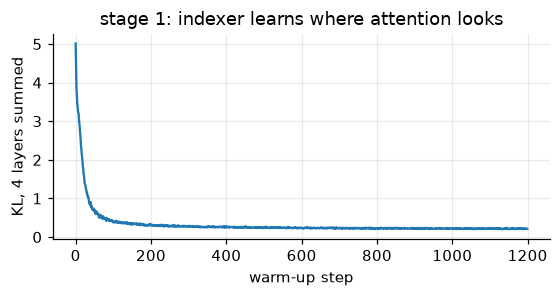

PASS - the warm-up reduces the indexer's KL by at least 30% 5.02 -> 0.21


In [7]:
def warmup(model, steps=1200, lr=2e-3, B=16):
    for n, p_ in model.named_parameters():
        p_.requires_grad = "indexer" in n
    set_mode(model, "dense", train_indexer=True)
    opt = torch.optim.Adam([p_ for p_ in model.parameters() if p_.requires_grad], lr=lr)
    g = torch.Generator().manual_seed(1)
    log = []
    for s in range(steps):
        seq = data.batch("train", B, T, g)
        model(seq[:, :-1])
        loss = sum(b.attn.kl for b in model.blocks)
        opt.zero_grad(); loss.backward(); opt.step()
        log.append(loss.item())
    for p_ in model.parameters():
        p_.requires_grad = True
    set_mode(model, "dense", train_indexer=False)
    return log

import copy
def clone(model):
    for b in model.blocks: b.attn.kl = None          # a loss tensor still holds its autograd graph and cannot be deep-copied
    return copy.deepcopy(model)
warm = clone(base)
log = warmup(warm)
print("indexer KL (sum over 4 layers) at step 0 / 300 / 600 / 1199:", [round(log[i], 2) for i in [0, 300, 600, 1199]])
fig, ax = plt.subplots(figsize=(5.2, 2.8)); ax.plot(log, color=C["blue"]); ax.set_xlabel("warm-up step"); ax.set_ylabel("KL, 4 layers summed")
ax.set_title("stage 1: indexer learns where attention looks"); plt.tight_layout(); plt.show()
check("the warm-up reduces the indexer's KL by at least 30%", log[-1] < 0.7 * log[0], f"{log[0]:.2f} -> {log[-1]:.2f}")

### How much of the attention does top-$k$ capture?

The direct test of the indexer: take validation text, run the *dense* model, and for each query look at how much of the (head-averaged) attention weight lies on the $k$ tokens the indexer picks. Compare with an **oracle** that picks the $k$ truly largest attention weights (the best possible), with the **$k$ most recent** tokens, and with **$k$ random** tokens. We read off every layer for $k=16$ and $k=32$, at query positions $\ge 64$ (so that there are always more than $k$ candidates).

k = 16  (of up to 127 tokens)
   oracle   per layer [0.32 0.52 0.81 0.81]   mean 0.62
   indexer  per layer [0.29 0.5  0.79 0.79]   mean 0.59
   local    per layer [0.21 0.41 0.74 0.74]   mean 0.52
   random   per layer [0.17 0.17 0.17 0.17]   mean 0.17
k = 32  (of up to 127 tokens)
   oracle   per layer [0.51 0.69 0.91 0.91]   mean 0.76
   indexer  per layer [0.48 0.67 0.9  0.89]   mean 0.73
   local    per layer [0.37 0.51 0.78 0.79]   mean 0.61
   random   per layer [0.34 0.34 0.35 0.34]   mean 0.34


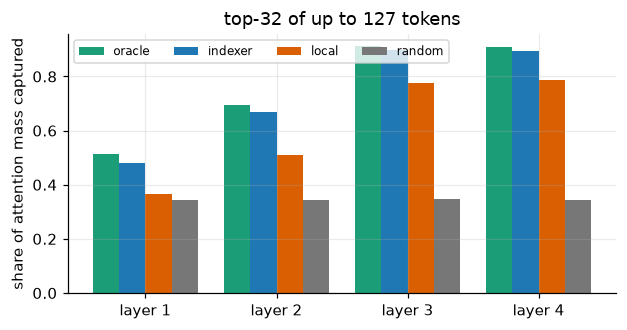

PASS - the trained indexer captures more attention mass than random selection in every layer (k=32) 
PASS - the oracle top-k is an upper bound on the indexer 


In [8]:
@torch.no_grad()
def capture(model, k, n_batches=6):
    set_mode(model, "dense", train_indexer=False)
    g = torch.Generator().manual_seed(9)
    out = {m: np.zeros(NL) for m in ["indexer", "oracle", "local", "random"]}
    model.eval()
    for _ in range(n_batches):
        seq = data.batch("val", 16, T, g)
        model(seq[:, :-1])
        for l, b in enumerate(model.blocks):
            p = b.attn.last_p.sum(1) / H                                  # [B,T,T] head-averaged
            I = b.attn.last_I
            Tq = p.shape[1]
            rows = slice(64, Tq)
            for name, mk in [("indexer", A.topk_mask(I, k)),
                             ("oracle", A.topk_mask(torch.where(torch.ones_like(p, dtype=torch.bool).tril(), p, torch.full_like(p, -1.0)), k)),
                             ("local", A.topk_mask((-(torch.arange(Tq)[:, None] - torch.arange(Tq)[None, :]).abs().float()).expand_as(p), k)),
                             ("random", A.topk_mask(torch.rand_like(p), k))]:
                out[name][l] += ((p * mk).sum(-1)[:, rows].mean().item()) / n_batches
    model.train()
    return out

cap = {k: capture(warm, k) for k in [16, 32]}
for k in [16, 32]:
    print(f"k = {k}  (of up to {T - 1} tokens)")
    for name in ["oracle", "indexer", "local", "random"]:
        print(f"   {name:8s} per layer {np.round(cap[k][name], 2)}   mean {cap[k][name].mean():.2f}")

fig, ax = plt.subplots(figsize=(5.8, 3.1))
w = .2
for i, name in enumerate(["oracle", "indexer", "local", "random"]):
    ax.bar(np.arange(NL) + (i - 1.5) * w, cap[32][name], w, label=name, color=[C["green"], C["blue"], C["orange"], C["grey"]][i])
ax.set_xticks(range(NL)); ax.set_xticklabels([f"layer {i + 1}" for i in range(NL)]); ax.set_ylabel("share of attention mass captured")
ax.set_title("top-32 of up to 127 tokens"); ax.legend(fontsize=8, ncol=4); plt.tight_layout(); plt.show()
check("the trained indexer captures more attention mass than random selection in every layer (k=32)",
      bool((cap[32]["indexer"] > cap[32]["random"]).all()))
check("the oracle top-k is an upper bound on the indexer", bool((cap[32]["oracle"] >= cap[32]["indexer"] - 1e-6).all()))

**Result (the table above; "mass" is the share of the head-averaged attention that lies on the selected tokens).** At $k=16$ the indexer's choice captures about 59% of the attention mass, against 62% for the oracle, 52% for the most recent 16 tokens and 17% for random tokens (random is the baseline you get just from the fraction of tokens kept). At $k=32$: 73% for the indexer, 76% for the oracle, 61% for the local window, 34% for random. So **the indexer is within about three points of the best possible choice and clearly above both baselines**, in every layer, from a network with a third of the attention layer's parameters.

*A lesson from building this.* Our first version of the indexer had **no positional information** (it read the layer input only). With that version the KL plateaued at about 2.3 and the indexer captured 39% at $k=16$ and 57% at $k=32$, *less* than the local window, and training it four times longer did not change that. The fix was not more training but giving the indexer rotary positions, after which the KL fell to about 0.2 and the numbers above appeared. In language models a lot of what attention reads is simply *the most recent tokens*, which an indexer cannot find without knowing where tokens are; this is why the paper's Figure 2 marks 'partially apply RoPE' on the indexer branch.

## 6. Experiment: what does it do to the language-modelling loss?

Now the question that matters. Starting from the warm-up model, we switch the attention to a sparse pattern and measure validation loss under four policies, each at $k\in\{8,16,32,64\}$: indexer top-$k$, the $k$ most recent tokens (local window), $k$ random tokens, and dense for reference. First **without** any further training (the model has never seen a sparse pattern), then after **stage 2, sparse training** (150 steps with the mask on, the whole model plus the indexer, following the paper's recipe):

In [9]:
def val(model, mode, k):
    set_mode(model, mode, k)
    return A.evaluate(model, data, T=T)

ks = [8, 16, 32, 64]
zero = {(m, k): val(warm, m, k) for m in ["topk", "local", "random"] for k in ks}
print(f"dense reference: {dense_loss:.3f}\n")
print(f"{'k':>4s} {'indexer top-k':>14s} {'local window':>14s} {'random':>10s}     (no sparse training yet)")
for k in ks:
    print(f"{k:4d} {zero[('topk', k)]:14.3f} {zero[('local', k)]:14.3f} {zero[('random', k)]:10.3f}")
set_mode(warm, "dense")

dense reference: 2.446

   k  indexer top-k   local window     random     (no sparse training yet)
   8          2.555          2.521      3.485
  16          2.499          2.468      3.255
  32          2.466          2.447      2.963
  64          2.449          2.447      2.630


In [10]:
def sparse_stage(model, mode, k, steps=150, lr=1e-3, B=16, seed=2):
    """stage 2: mask on; main model trained on the LM loss, indexer on eq. 4 (only matters when mode == 'topk')."""
    set_mode(model, mode, k, train_indexer=(mode == "topk"))
    def hook(s, m, seq):
        return sum(b.attn.kl for b in m.blocks) if mode == "topk" else 0.0
    A.train_lm(model, data, steps=steps, B=B, T=T, lr=lr, seed=seed, hook=hook)
    set_mode(model, mode, k, train_indexer=False)
    return A.evaluate(model, data, T=T)

after = {}
t0 = time.time()
for k in [16, 32]:
    for mode in ["topk", "local", "random"]:
        m = clone(warm)
        after[(mode, k)] = sparse_stage(m, mode, k)
        print(f"k={k:2d} {mode:7s} after sparse training: {after[(mode, k)]:.3f}   (before: {zero[(mode, k)]:.3f})")
# control: the same 150 steps of extra training on the DENSE model, to separate "more training" from "sparse adaptation"
ctl = clone(warm); set_mode(ctl, "dense")
A.train_lm(ctl, data, steps=150, B=16, T=T, lr=1e-3, seed=2)
ctl_loss = A.evaluate(ctl, data, T=T)
print(f"dense, 150 more steps (control): {ctl_loss:.3f}   ({time.time() - t0:.0f} s)")

k=16 topk    after sparse training: 2.381   (before: 2.499)


k=16 local   after sparse training: 2.374   (before: 2.468)


k=16 random  after sparse training: 2.868   (before: 3.255)


k=32 topk    after sparse training: 2.379   (before: 2.466)


k=32 local   after sparse training: 2.366   (before: 2.447)


k=32 random  after sparse training: 2.711   (before: 2.963)


dense, 150 more steps (control): 2.374   (126 s)


**Result (validation loss in nats; the dense model scores 2.446, and 150 further dense steps give 2.374).** *Without any sparse training*, switching on the indexer's top-$k$ costs 0.11 nats at $k=8$, 0.05 at $k=16$, 0.02 at $k=32$ and 0.003 at $k=64$ (2.555, 2.499, 2.466, 2.449). The most recent $k$ tokens cost slightly less at every $k$ (2.521, 2.468, 2.447, 2.447), and random tokens are far worse (3.49, 3.26, 2.96, 2.63). *After 150 steps of sparse training* the gap closes almost completely: indexer top-$k$ reaches 2.381 at $k=16$ and 2.379 at $k=32$, the local window 2.374 and 2.366, the dense control 2.374, and random 2.87 and 2.71.

How to read this. (1) The sparse pattern is nearly free here: after a short adaptation, attending to a quarter of the tokens ($k=32$ of up to 127) is within 0.005 nats of the dense control. (2) The indexer is far better than random and close to the oracle on captured mass, but in loss the **local window is as good or slightly better** in our toy. The honest reason is that character-level text is mostly local: the most recent 32 tokens already hold 61% of the attention, so there is little for a smarter selector to find. (3) So this toy **cannot show the benefit that motivates DSA**, picking out far-away relevant tokens from a very long context. It does show the pieces working: the indexer learns the attention's distribution, its top-$k$ is much better than random and tracks the oracle, and the model adapts to sparsity within a few hundred steps.

## 7. The cost model

All of the above is about quality. The reason for DSA is cost, so we write the cost down. Per query token at position $t$, per layer, in multiply-adds for the *score* step (the part that scales with context), with $c_a$ the cost per (query, key) pair of the main attention and $c_i$ that of the indexer:

$$ \text{dense: } c_a\,t \qquad\qquad \text{DSA: } c_i\,t + c_a\,\min(k,t) $$

DSA wins when $c_i t + c_a k < c_a t$, i.e. $t > k\,/\,(1 - c_i/c_a)$: the saving only exists after the context passes about $k$ tokens, and for $t\gg k$ it tends to a factor $c_a/c_i$ (the indexer's cost is what is left). For our toy dimensions, $c_a = H d_h = 64$ and $c_i = h_I d_I + h_I = 68$ from section 2, so our toy indexer is **not** cheaper than its attention, and in this toy DSA would never save compute. In DeepSeek-V3.2 the indexer is built to be much cheaper than main attention (it is small, uses few heads and runs in FP8, and the main attention it replaces is MLA with 128 heads); the paper's Figure 3 shows the effect on real H800 serving cost:

![The paper's Figure 3: inference cost per million tokens of DeepSeek-V3.1-Terminus and DeepSeek-V3.2 on H800 GPUs, against the token position in the sequence (prefilling on the left, decoding on the right). Dense attention's cost per token grows linearly with position; DSA's is nearly flat.](../../assets/architecture_gallery/dsa_fig3_cost.png)

The curve of dense attention rises with position and DSA's stays low and nearly flat; we cannot reproduce those numbers, as they need GPU kernels, so the cell below only plots the formula with an *assumed* indexer-to-attention cost ratio, to show the shape.

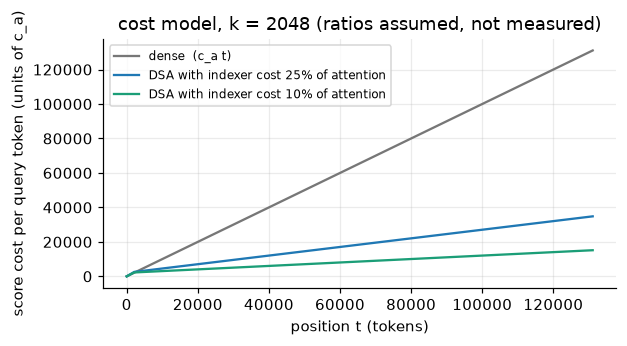

break-even position for indexer/attention cost 0.25: 2730 ; for 0.10: 2275
PASS - break-even is just above k when the indexer is cheap 
PASS - the saving at t = 128K tends to the cost ratio, never more 


In [11]:
t = np.arange(1, 131073)
kk = 2048
fig, ax = plt.subplots(figsize=(5.8, 3.2))
ax.plot(t, t, color=C["grey"], label="dense  (c_a t)")
for ratio, col in [(0.25, C["blue"]), (0.1, C["green"])]:
    ax.plot(t, ratio * t + np.minimum(kk, t), color=col, label=f"DSA with indexer cost {ratio:.0%} of attention")
ax.set_xlabel("position t (tokens)"); ax.set_ylabel("score cost per query token (units of c_a)")
ax.set_title("cost model, k = 2048 (ratios assumed, not measured)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
t_star = lambda ratio: kk / (1 - ratio)
print("break-even position for indexer/attention cost 0.25:", int(t_star(0.25)), "; for 0.10:", int(t_star(0.10)))
check("break-even is just above k when the indexer is cheap", t_star(0.1) < 1.2 * kk)
check("the saving at t = 128K tends to the cost ratio, never more", (131072 / (0.1 * 131072 + kk)) < 10)

## What this notebook did and did not show

**Shown (checks).** The indexer's score is one value per (query, earlier token) pair with a small parameter and per-pair cost budget; the selection is a mask on top of ordinary attention and equals dense attention when $k\ge t$; the KL loss is zero for a perfect indexer; the dense warm-up lowers the KL; and the trained indexer captures more of the attention than random selection in every layer. Sections 5 and 6 contain the capture and loss numbers and what they say.

**Not shown.** DeepSeek-V3.2's claim that quality is preserved at $k=2048$ over 128K contexts after 943.7B tokens of continued training, and its real serving costs (their Figure 3), which need an MLA model and GPU kernels. Our contexts are 128 characters, our $k$ is 8 to 64, and our toy indexer is not cheaper than its attention (section 7), so nothing here says anything about cost. We did not implement MLA-based sharing of key-value entries, FP8 indexer arithmetic, or the paper's distinction between prefilling and decoding kernels.

**Next.** Notebook 5 changes the layer itself: replace softmax attention with a linear recurrence that carries a fixed-size memory, the (gated) delta rule.

In [12]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 12 | failed: 0
